# DEV · CardioRitmo: tamizaje de latidos (ECG5000)
**Responsable:** Francisco

**Especificaciones del cliente (prueba, umbral 0.5):** sensibilidad ≥ 0.95 · especificidad ≥ 0.95 · ≤ 20,000 parámetros entrenables.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # menos ruido en las salidas
import random, numpy as np, tensorflow as tf
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

def fijar_semillas():
    """Se llama antes de construir cada modelo para que cada uno sea reproducible por separado."""
    random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow", tf.__version__)

I0000 00:00:1794091875.450506   19525 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794091875.451842   19525 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794091878.200813   19525 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794091878.201655   19525 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0


## 1. Datos (carga y división exactas del enunciado)

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

ecg = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv",
                  header=None)
X = ecg.iloc[:, :-1].to_numpy("float32")       # 140 puntos por latido
y = 1 - ecg.iloc[:, -1].to_numpy("int64")      # el archivo trae 1 = normal; aquí 1 = ANORMAL

# Prueba del cliente: 20 % estratificado. No la toquen hasta el final.
X_resto, X_prueba, y_resto, y_prueba = train_test_split(X, y, test_size=0.2, stratify=y,
                                                        random_state=42)
# Con X_resto y y_resto armen su entrenamiento y su validación como quieran.

## 2. Exploración
Tamaño, balance de clases, ejemplos y al menos 2 gráficas.

Forma: (4998, 140)
Balance (1 = anormal): {0: 0.584, 1: 0.416}
Rango de valores: [-7.09, 7.40]  ·  media global -0.000
Valores faltantes: 0


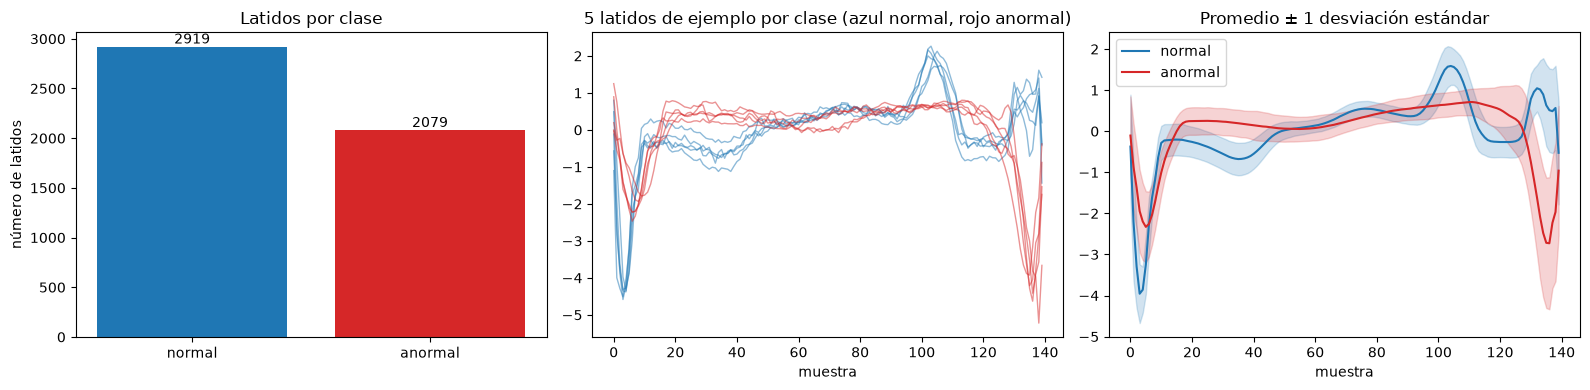

In [3]:
import matplotlib.pyplot as plt
print("Forma:", X.shape)
print("Balance (1 = anormal):", pd.Series(y).value_counts(normalize=True).round(3).to_dict())
print(f"Rango de valores: [{X.min():.2f}, {X.max():.2f}]  ·  media global {X.mean():.3f}")
print("Valores faltantes:", int(np.isnan(X).sum()))

nombres = {0: "normal", 1: "anormal"}
colores = {0: "tab:blue", 1: "tab:red"}
t = np.arange(X.shape[1])

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
conteo = pd.Series(y).map(nombres).value_counts()
ax[0].bar(conteo.index, conteo.values, color=["tab:blue", "tab:red"])
ax[0].set_title("Latidos por clase"); ax[0].set_ylabel("número de latidos")
for k, v in enumerate(conteo.values): ax[0].text(k, v, str(v), ha="center", va="bottom")

for c in (0, 1):
    for fila in X[y == c][:5]:
        ax[1].plot(t, fila, color=colores[c], alpha=0.5, lw=1)
ax[1].set_title("5 latidos de ejemplo por clase (azul normal, rojo anormal)"); ax[1].set_xlabel("muestra")

for c in (0, 1):
    mu, sd = X[y == c].mean(0), X[y == c].std(0)
    ax[2].plot(t, mu, color=colores[c], label=nombres[c])
    ax[2].fill_between(t, mu - sd, mu + sd, color=colores[c], alpha=0.2)
ax[2].set_title("Promedio ± 1 desviación estándar"); ax[2].set_xlabel("muestra"); ax[2].legend()
plt.tight_layout(); plt.show()

**Lectura de la exploración:** son 4,998 latidos de 140 puntos, ya segmentados y normalizados, sin faltantes. El 41.6 % son anormales, así que las clases están moderadamente desbalanceadas pero no tanto como para necesitar `class_weight` de entrada. Los promedios por clase se separan claramente, sobre todo después del complejo QRS (≈ muestras 60–120): el latido normal se recupera y el anormal se queda abajo. Eso sugiere que incluso modelos pequeños pueden cumplir.

## 3. Preparación
Validación estratificada (20 %) desde `X_resto`. Los datos ya vienen normalizados por latido, así que no se ajusta ningún escalador (y por lo tanto no hay riesgo de fuga desde validación o prueba).

In [4]:
X_tr, X_val, y_tr, y_val = train_test_split(X_resto, y_resto, test_size=0.2,
                                            stratify=y_resto, random_state=42)
X_tr_s, X_val_s, X_prueba_s = (a[..., None] for a in (X_tr, X_val, X_prueba))  # (n, 140, 1) para Conv1D/RNN
print(X_tr.shape, X_val.shape, X_prueba.shape)
print("Proporción de anormales  train %.3f · val %.3f · prueba %.3f" % (y_tr.mean(), y_val.mean(), y_prueba.mean()))

(3198, 140) (800, 140) (1000, 140)
Proporción de anormales  train 0.416 · val 0.416 · prueba 0.416


## 4. Métricas del cliente

In [5]:
from sklearn.metrics import confusion_matrix, roc_auc_score

def metricas(y_true, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    sens, esp = tp / (tp + fn), tn / (tn + fp)
    auc = roc_auc_score(y_true, prob) if len(set(prob)) > 1 else 0.5
    return {"sensibilidad": sens, "especificidad": esp, "auc": auc,
            "cumple_metricas": sens >= 0.95 and esp >= 0.95}

## 5. Línea base

In [6]:
from sklearn.dummy import DummyClassifier
base = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
prob_val = {"Línea base (clase más frecuente)": base.predict_proba(X_val)[:, 1]}
print(metricas(y_val, prob_val["Línea base (clase más frecuente)"]))

{'sensibilidad': np.float64(0.0), 'especificidad': np.float64(1.0), 'auc': 0.5, 'cumple_metricas': np.False_}


La línea base siempre dice "normal": especificidad 1.0 pero sensibilidad 0.0. No detecta ningún latido anormal, que es justo lo que el cliente necesita.

## 6. Modelos (≤ 20,000 parámetros cada uno)
Tres familias, todas con salida sigmoide, `binary_crossentropy`, Adam (1e-3), lotes de 32 y EarlyStopping sobre `val_loss` (paciencia 10, se restauran los mejores pesos).

- **MLP** 140→64→32→1: trata el latido como un vector plano. *Nota sobre `tipo`:* la lista permitida no tiene "densa/MLP"; usamos `embeddings`, la categoría más cercana y la misma que usó Reseñas para TF-IDF + densa.
- **Conv1D** (`convolucional`): tres capas convolucionales pequeñas + promedio global; aprovecha que la forma local del latido importa.
- **GRU(32)** (`recurrente`): recorre el latido punto por punto.

In [7]:
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd

def hacer_mlp():
    return keras.Sequential([keras.Input((140,)),
                             layers.Dense(64, activation="relu"), layers.Dropout(0.2),
                             layers.Dense(32, activation="relu"),
                             layers.Dense(1, activation="sigmoid")], name="mlp")

def hacer_conv1d():
    return keras.Sequential([keras.Input((140, 1)),
                             layers.Conv1D(8, 7, activation="relu", padding="same"), layers.MaxPooling1D(2),
                             layers.Conv1D(16, 5, activation="relu", padding="same"), layers.MaxPooling1D(2),
                             layers.Conv1D(16, 3, activation="relu", padding="same"),
                             layers.GlobalAveragePooling1D(),
                             layers.Dense(1, activation="sigmoid")], name="conv1d")

def hacer_gru():
    return keras.Sequential([keras.Input((140, 1)), layers.GRU(32),
                             layers.Dense(1, activation="sigmoid")], name="gru")

# nombre -> (constructor, tipo, ¿usa (n,140,1)?)
especificacion = {
    "MLP 140→64→32→1": (hacer_mlp, "embeddings", False),
    "Conv1D pequeño": (hacer_conv1d, "convolucional", True),
    "GRU(32)": (hacer_gru, "recurrente", True),
}

modelos, historias = {}, {}
for nombre, (hacer, tipo, secuencia) in especificacion.items():
    fijar_semillas()
    m = hacer()
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    a, b = (X_tr_s, X_val_s) if secuencia else (X_tr, X_val)
    h = m.fit(a, y_tr, validation_data=(b, y_val), epochs=200, batch_size=32, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=10, restore_best_weights=True)])
    modelos[nombre], historias[nombre] = m, h.history
    prob_val[nombre] = m.predict(b, verbose=0).ravel()
    print(f"{nombre:18s} {m.count_params():>6,} parámetros · {len(h.history['loss'])} épocas")

params = {"Línea base (clase más frecuente)": 0, **{n: m.count_params() for n, m in modelos.items()}}
tipos = {"Línea base (clase más frecuente)": "linea base", **{n: e[1] for n, e in especificacion.items()}}

val = pd.DataFrame([{"modelo": n, "tipo": tipos[n], "parametros": params[n], **metricas(y_val, p)}
                    for n, p in prob_val.items()])
val["cumple"] = val["cumple_metricas"] & (val["parametros"] <= 20_000)
val.drop(columns="cumple_metricas").round(4)

MLP 140→64→32→1    11,137 parámetros · 15 épocas


Conv1D pequeño      1,521 parámetros · 118 épocas


GRU(32)             3,393 parámetros · 69 épocas


,modelo,tipo,parametros,sensibilidad,especificidad,auc,cumple
0,Línea base (clase más frecuente),linea base,0,0.000,1.0000,0.5000,False
1,MLP 140→64→32→1,embeddings,11137,0.985,0.9893,0.9985,True
2,Conv1D pequeño,convolucional,1521,0.967,0.9936,0.9993,True
3,GRU(32),recurrente,3393,0.976,0.9914,0.9986,True


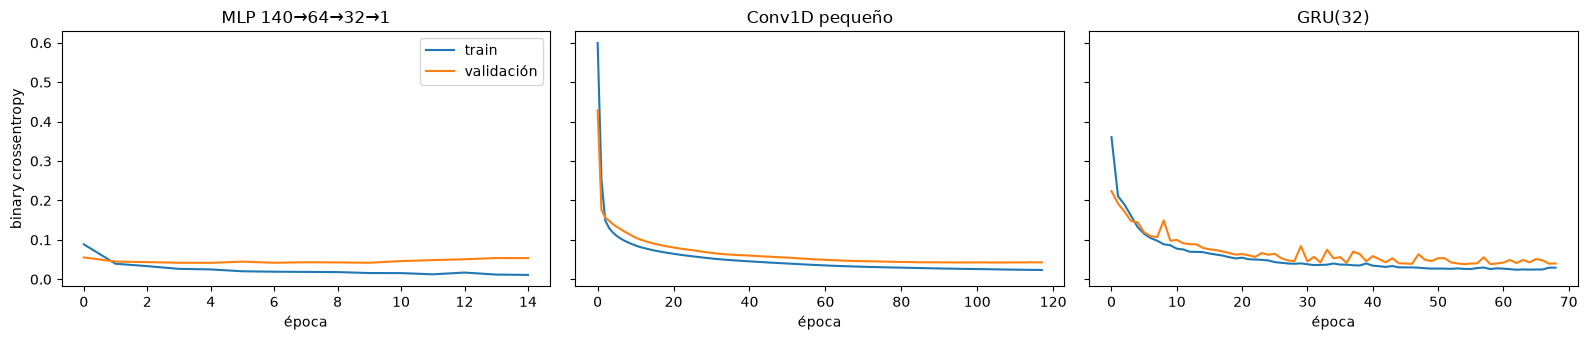

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5), sharey=True)
for a, (n, h) in zip(ax, historias.items()):
    a.plot(h["loss"], label="train"); a.plot(h["val_loss"], label="validación")
    a.set_title(n); a.set_xlabel("época")
ax[0].set_ylabel("binary crossentropy"); ax[0].legend(); plt.tight_layout(); plt.show()

### Elección (solo con validación)
Regla: entre los modelos que cumplen **con margen** (sensibilidad y especificidad ≥ 0.96 en validación, un punto arriba de la especificación, y ≤ 20,000 parámetros), se elige el que tenga **menos parámetros**. El margen cubre la variación natural entre validación (800 latidos) y prueba (1,000 latidos).

In [9]:
MARGEN = 0.96
candidatos = val[(val["sensibilidad"] >= MARGEN) & (val["especificidad"] >= MARGEN) & (val["parametros"] <= 20_000)]
elegido = candidatos.sort_values("parametros").iloc[0]["modelo"]
modelo_elegido = modelos[elegido]
print("Cumplen con margen:", list(candidatos["modelo"]))
print("Elegido:", elegido, f"({params[elegido]:,} parámetros)")

Cumplen con margen: ['MLP 140→64→32→1', 'Conv1D pequeño', 'GRU(32)']
Elegido: Conv1D pequeño (1,521 parámetros)


## 7. Evaluación única en prueba y `resultados`

In [10]:
# Evaluación ÚNICA en prueba: los modelos ya están congelados y la elección ya se hizo arriba.
prob_prueba = {"Línea base (clase más frecuente)": base.predict_proba(X_prueba)[:, 1]}
for nombre, (_, _, secuencia) in especificacion.items():
    prob_prueba[nombre] = modelos[nombre].predict(X_prueba_s if secuencia else X_prueba, verbose=0).ravel()

filas = []
for n, p in prob_prueba.items():
    r = metricas(y_prueba, p)
    filas.append({"modelo": n, "tipo": tipos[n], "parametros": params[n],
                  "sensibilidad": round(r["sensibilidad"], 4), "especificidad": round(r["especificidad"], 4),
                  "auc": round(r["auc"], 4),
                  "cumple": bool(r["cumple_metricas"] and params[n] <= 20_000),
                  "elegido": n == elegido})
resultados = pd.DataFrame(filas, columns=["modelo","tipo","parametros","sensibilidad","especificidad","auc","cumple","elegido"])
resultados.to_csv("resultados_ecg.csv", index=False)
resultados

,modelo,tipo,parametros,sensibilidad,especificidad,auc,cumple,elegido
0,Línea base (clase más frecuente),linea base,0,0.0000,1.0000,0.5000,False,False
1,MLP 140→64→32→1,embeddings,11137,0.9832,1.0000,0.9980,True,False
2,Conv1D pequeño,convolucional,1521,0.9784,0.9966,0.9979,True,True
3,GRU(32),recurrente,3393,0.9856,0.9949,0.9965,True,False


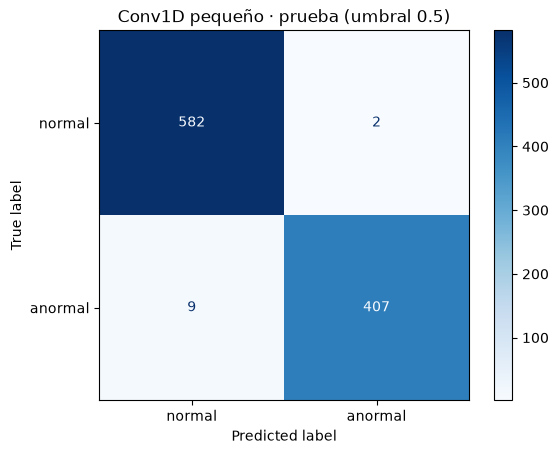

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
pred_prueba = (prob_prueba[elegido] >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(y_prueba, pred_prueba, display_labels=["normal", "anormal"], cmap="Blues")
plt.title(f"{elegido} · prueba (umbral 0.5)"); plt.show()

## 8. Justificación de la elección
Se eligió el **Conv1D pequeño (1,521 parámetros)** con la regla fijada *antes* de ver la prueba: en validación, los tres modelos cumplían con margen (sensibilidad y especificidad ≥ 0.96) y el Conv1D es el que menos parámetros usa, 7 veces menos que el MLP y la mitad que el GRU. Su AUC en validación (0.9993) fue además la más alta.

**En prueba (una sola evaluación, umbral 0.5) cumple las tres especificaciones:**

| Especificación | Requisito | Conv1D en prueba | ¿Cumple? |
|---|---|---|---|
| Sensibilidad | ≥ 0.95 | **0.978** (407 de 416 latidos anormales detectados) | Sí |
| Especificidad | ≥ 0.95 | **0.997** (582 de 584 latidos normales correctos) | Sí |
| Parámetros entrenables | ≤ 20,000 | **1,521** | Sí |

En palabras del cliente: *de cada 100 latidos anormales, el modelo marca 98; de cada 100 normales, da falsa alarma en menos de 1.*

En prueba, el MLP y el GRU tuvieron una sensibilidad algo mayor (0.983 y 0.986), pero la elección no se cambia después de ver la prueba: hacerlo sería usarla para decidir. Además, las diferencias son de 2 a 3 latidos sobre 416.

## 9. Análisis de 3 errores

Errores del modelo elegido en prueba: 9 FN y 2 FP de 1000 latidos


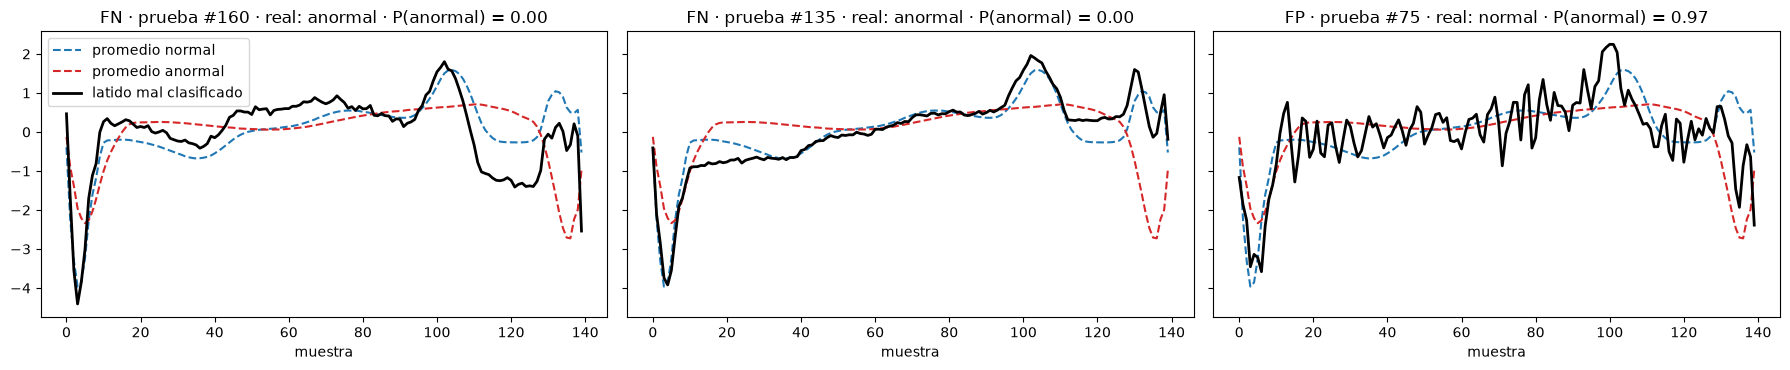

In [12]:
p = prob_prueba[elegido]
fn_idx = np.where((y_prueba == 1) & (pred_prueba == 0))[0]   # anormal que el modelo dejó pasar
fp_idx = np.where((y_prueba == 0) & (pred_prueba == 1))[0]   # normal marcado como anormal
print(f"Errores del modelo elegido en prueba: {len(fn_idx)} FN y {len(fp_idx)} FP de {len(y_prueba)} latidos")

# Los errores más "seguros" (más lejos de 0.5) son los más informativos: 2 FN y 1 FP si existen.
fn_orden = fn_idx[np.argsort(p[fn_idx])]          # FN con probabilidad más baja primero
fp_orden = fp_idx[np.argsort(-p[fp_idx])]         # FP con probabilidad más alta primero
n_fn = min(2, len(fn_orden)); n_fp = min(3 - n_fn, len(fp_orden))
casos = [("FN", i) for i in fn_orden[:n_fn]] + [("FP", i) for i in fp_orden[:n_fp]]

prom = {c: X_tr[y_tr == c].mean(0) for c in (0, 1)}   # promedios de clase calculados solo con train
fig, ax = plt.subplots(1, len(casos), figsize=(6 * len(casos), 3.8), sharey=True)
ax = np.atleast_1d(ax)
for a, (clase_err, i) in zip(ax, casos):
    real = int(y_prueba[i])
    a.plot(t, prom[0], color="tab:blue", ls="--", label="promedio normal")
    a.plot(t, prom[1], color="tab:red", ls="--", label="promedio anormal")
    a.plot(t, X_prueba[i], color="black", lw=2, label="latido mal clasificado")
    a.set_title(f"{clase_err} · prueba #{i} · real: {nombres[real]} · P(anormal) = {p[i]:.2f}")
    a.set_xlabel("muestra")
ax[0].legend(); plt.tight_layout(); plt.show()

**Lectura de los errores** (11 en total sobre 1,000 latidos: 9 FN y 2 FP):

1. **FN #160, P(anormal) = 0.00.** Tiene el pico R alrededor de la muestra 100, igual que el promedio normal, y por eso el modelo lo da por normal con toda seguridad. Lo anormal aparece solo al final (muestras 110–130), donde se queda abajo en lugar de recuperarse. Es una anomalía tardía y parcial que la red, con su promedio global, diluye.
2. **FN #135, P(anormal) = 0.00.** Es prácticamente indistinguible del promedio normal en todo el recorrido. Puede tratarse de un latido con una anomalía muy sutil o de una **etiqueta dudosa** en el conjunto. Ningún modelo basado solo en la forma lo detectaría.
3. **FP #75, P(anormal) = 0.97.** Es un latido normal con **mucho ruido** de alta frecuencia y oscilaciones. El modelo confunde el ruido con irregularidad. Esto muestra una debilidad práctica: una señal mal adquirida (electrodo flojo, movimiento) puede generar falsas alarmas.

**Riesgo para el cliente:** los FN son el error caro, porque un latido anormal pasa sin revisión. Los dos FN más seguros tienen probabilidad ≈ 0, así que bajar el umbral no los rescataría (y el umbral está fijo en 0.5 de todos modos).

## 10. Guardar el modelo elegido

In [13]:
import os
os.makedirs("modelo", exist_ok=True)
modelo_elegido.save("modelo/modelo_ecg.keras")

# Verificación: el modelo recargado da exactamente las mismas probabilidades
recargado = keras.models.load_model("modelo/modelo_ecg.keras")
entrada = X_prueba_s if especificacion[elegido][2] else X_prueba
print("Guardado:", elegido, "·", f"{os.path.getsize('modelo/modelo_ecg.keras') / 1024:.0f} KB",
      "· predicciones idénticas:", np.allclose(recargado.predict(entrada, verbose=0).ravel(), prob_prueba[elegido]))

Guardado: Conv1D pequeño · 55 KB · predicciones idénticas: True


## 11. Limitaciones
- **Un solo paciente.** ECG5000 viene de un único paciente con insuficiencia cardiaca. El desempeño (sensibilidad 0.978) no se puede extrapolar a otras personas, edades o equipos sin validarlo con nuevos pacientes.
- **Latidos ya segmentados y normalizados.** En producción habría que detectar y recortar cada latido del trazo continuo y normalizarlo igual; un error en ese paso no está medido aquí.
- **Etiqueta binaria.** "Anormal" agrupa cuatro clases originales (R-on-T, PVC, latido supraventricular y no clasificado). El modelo no dice *qué* anomalía es.
- **Sensibilidad al ruido** (FP #75) y **anomalías sutiles o tardías** (FN #160, #135). De 416 anormales en prueba se escapan 9.
- **Uso:** es una herramienta de **tamizaje** para priorizar la revisión del cardiólogo, no un diagnóstico.